# Default clustering: where the binomial test is misused, and BCBS Working Paper 14 rerun

**Question:** How much does a small asset correlation inflate the false-alarm rate of the tests that assume independent defaults, and does the engine reproduce what BCBS Working Paper 14 printed for them?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic (the rate, the size of every test, the exact rejection probabilities)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- compute the default correlation that an asset correlation implies and the factor by which it inflates the variance of a default count;
- read the exact size of the binomial, Jeffreys and Vasicek-corrected tests under clustering, and say which of them breaks first;
- measure by simulation the size of the tests that have no closed form as the asset correlation grows;
- recompute the true confidence of a 99.9% binomial test with the engine and compare it with the approximation of BCBS Working Paper 14;
- rerun a scenario of the paper with a new seed and judge, cell by cell, whether the engine reproduces what the paper printed.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `clustering` family of case C22, validating the validator. In every dataset the PDs the tests are given are exactly right, and the defaults share one systematic factor with an asset correlation $\rho$ on a ladder from 0 to 20%. A rejection is therefore always a false alarm, and its rate is the true size of the test under clustering. The family also holds, under `golden`, the published rates of BCBS Working Paper 14, Tables 7 and 8 (144 cells), quoted from the paper. The datasets come from known-truth generators of `riskvalidation.generators` (licence MIT, class `generated`).

- **File read:** `data/derived/C22/clustering.json`, keys `outputs` (simulations, generators, ladder, the exact curve and the published cells) and `provenance`.
- **What is taken from it:** the configuration and seed of each rung, the grid of PDs of the paper's figure and its published rates.

The next cell loads the file and prints the ladder with the engine versions.

In [2]:
# Load the clustering family and index its simulations by key
LANG = "en"
ROOT = Path("../../..").resolve()
clustering = json.loads((ROOT / "data" / "derived" / "C22" / "clustering.json").read_text(encoding="utf-8"))
out = clustering["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]
print("asset correlations of the ladder:", ladder)
print("baked by riskvalidation", clustering["provenance"]["riskvalidation_version"])
print("installed", rv.__version__)

asset correlations of the ladder: [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]
baked by riskvalidation 1.0.1
installed 1.0.1


## Method

**One systematic factor.** In the one-factor model of the working paper, and of Vasicek, obligor $i$ defaults when its asset value falls below a threshold, and the asset values share a factor $x \sim N(0,1)$ with correlation $\rho$. Given $x$ the defaults are independent with the conditional PD

$$p(x) = \Phi\!\left(\frac{\Phi^{-1}(\pi) - \sqrt{\rho}\,x}{\sqrt{1-\rho}}\right),$$

and the default count of $n$ obligors has variance $n\pi(1-\pi)\,[1 + (n-1)\rho_D]$, where $\rho_D$ is the default correlation. A test that fixes its critical value as if $\rho_D$ were zero rejects too often, because the real spread of the count is the larger one. The steps measure how much, for the count tests exactly and for the others by simulation, and then check the engine against the paper.

### Step 1: a small default correlation, a large variance

The engine's `default_correlation` evaluates $\rho_D$ for a PD and an asset correlation. The next cell prints it for each rung at a PD of 1%, with the variance factor $1 + (n-1)\rho_D$ for 1,000 obligors, and draws the factor over a fine grid of asset correlations.

asset correlation 0.00 | default correlation 0.000%
   variance factor 1.00
asset correlation 0.02 | default correlation 0.151%
   variance factor 2.51
asset correlation 0.05 | default correlation 0.410%
   variance factor 5.10
asset correlation 0.10 | default correlation 0.936%
   variance factor 10.35
asset correlation 0.15 | default correlation 1.597%
   variance factor 16.95
asset correlation 0.20 | default correlation 2.413%
   variance factor 25.11


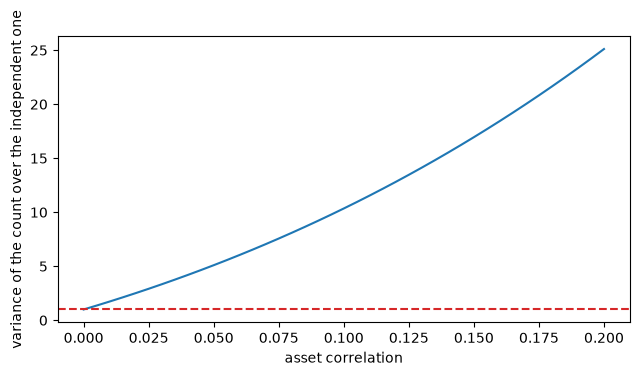

In [3]:
# Default correlation implied by each asset correlation and the variance inflation of the count
from riskvalidation.generators.counts import default_correlation

grid = np.linspace(0.0, 0.2, 41)
inflation = [1 + 999 * (default_correlation(0.01, r) if r > 0 else 0.0) for r in grid]
for rho in ladder:
    rho_d = default_correlation(0.01, rho) if rho > 0 else 0.0
    print(f"asset correlation {rho:.2f} | default correlation {100 * rho_d:.3f}%")
    print(f"   variance factor {1 + 999 * rho_d:.2f}")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(grid, inflation)
ax.axhline(1.0, color="tab:red", linestyle="--")
ax.set_xlabel("asset correlation")
ax.set_ylabel("variance of the count over the independent one")
fig.tight_layout()
plt.show()

An asset correlation of 5% is a default correlation of only 0.410%, and yet it multiplies the variance of the default count by 5.10 for a portfolio of 1,000 obligors. At 10% the factor is 10.35 and at 20% it reaches 25.11. The curve is almost a straight line in $\rho$ because $\rho_D$ grows about in proportion to it, and the factor grows with the number of obligors as well. A test that takes the count to have the independent variance is looking at a spread that is five to twenty-five times too small.

### Step 2: the exact size of the count tests under clustering

The next cell asks `rejection_probability` for the exact size at 5% of the binomial, Jeffreys and Vasicek-corrected tests for 1,000 obligors at a PD of 1% that is exactly right, as the true asset correlation rises from 0 to 20%. The corrected test assumes a correlation of 12%. The cell prints the sizes at four correlations and draws all three over a grid of 21 values.

pd.binomial          [0.0479, 0.1775, 0.1969, 0.1911]
pd.jeffreys          [0.0479, 0.1775, 0.1969, 0.1911]
pd.binomial_vasicek  [0.0, 0.0146, 0.0414, 0.0711]
asset correlation of those sizes: [0.0, 0.05, 0.1, 0.2]


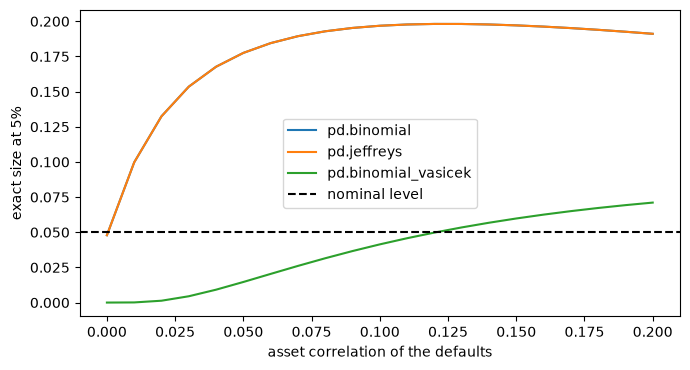

In [4]:
# Exact size at 5% of the three count tests along the asset-correlation ladder
from riskvalidation.harness.exact import rejection_probability

count_tests = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
fine = np.linspace(0.0, 0.2, 21)
sizes = {}
for test, kw in count_tests.items():
    exact = [rejection_probability(test, 1000, 0.01, 0.05, pd_true=0.01, rho_true=r, **kw) for r in fine]
    sizes[test] = [item["probability"] for item in exact]
    print(f"{test:20s}", [round(sizes[test][i], 4) for i in (0, 5, 10, 20)])
print("asset correlation of those sizes:", [round(float(fine[i]), 2) for i in (0, 5, 10, 20)])
fig, ax = plt.subplots(figsize=(7, 3.8))
for test in count_tests:
    ax.plot(fine, sizes[test], label=test)
ax.axhline(0.05, color="black", linestyle="--", label="nominal level")
ax.set_xlabel("asset correlation of the defaults")
ax.set_ylabel("exact size at 5%")
ax.legend()
fig.tight_layout()
plt.show()

The binomial and Jeffreys tests share one curve at 5%, since both reject from the same count. Their exact size rises from 0.0479 with independent defaults to 0.1775 at an asset correlation of 5%, 0.1969 at 10% and 0.1911 at 20%: a test sold as 5% rejects a right model about one time in five. The corrected test is below its level when the true correlation is smaller than the assumed one, with 0.0146 at 5%, and passes it only beyond 12%, with 0.0711 at 20%. The correction is no cure for a wrong correlation, only for the right one.

### Step 3: the tests with no closed form

The chi-square test over seven grades, Hosmer-Lemeshow (1980) and Spiegelhalter (1986) all assume independent defaults, and the multi-year normal test and the traffic lights are the working paper's tests for time series. For them the only measurement is a simulated rate. The next cell rebuilds the generator of each rung from the file, simulates each test with 1,000 repetitions, prints the sizes along the ladder and draws them against the nominal 5%.

pd.chi2_grades           [0.039, 0.476, 0.665, 0.745, 0.833, 0.871]
pd.hosmer_lemeshow       [0.051, 0.514, 0.633, 0.764, 0.829, 0.868]
pd.spiegelhalter         [0.038, 0.308, 0.354, 0.311, 0.353, 0.344]
pd.normal_multiperiod    [0.083, 0.091, 0.077, 0.056, 0.034, 0.039]
pd.traffic_lights        [0.037, 0.108, 0.109, 0.107, 0.074, 0.06]


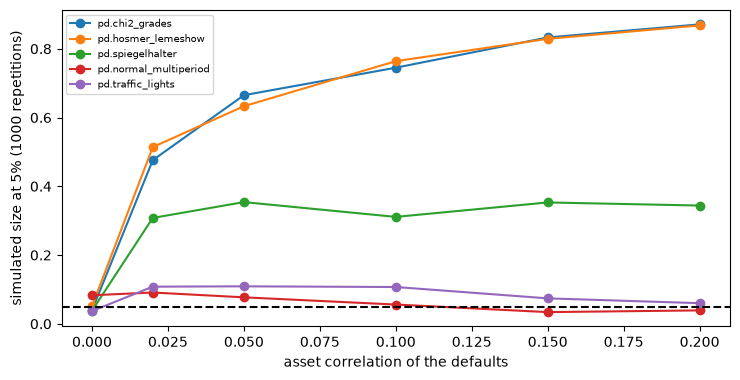

In [5]:
# Simulate the five tests with no closed form along the ladder and draw their size
from riskvalidation.generators.counts import DefaultCounts, feed_grades, feed_series
from riskvalidation.generators.scores import LogisticPortfolio
from riskvalidation.harness.run import simulate

CLASSES = {cls.name: cls for cls in (DefaultCounts, LogisticPortfolio)}
open_tests = ("pd.chi2_grades", "pd.hosmer_lemeshow", "pd.spiegelhalter", "pd.normal_multiperiod", "pd.traffic_lights")
fig, ax = plt.subplots(figsize=(7.5, 3.9))
for test in open_tests:
    rates = []
    for rho in ladder:
        row = rows[f"{test}@rho{rho:g}"]
        cfg = out["generators"][row["generator"]]
        shape = cfg["config"].get("obligors", [[0]])
        feed = feed_series() if len(shape) > 1 else feed_grades()
        generator = CLASSES[cfg["name"]](**cfg["config"])
        feed = None if cfg["name"] == "logistic_portfolio" else feed
        run = simulate(test, generator, n_rep=1000, seed=row["seed"], feed=feed)
        rates.append(run.rates["p<0.05"].rate)
    ax.plot(ladder, rates, "o-", label=test)
    print(f"{test:24s}", [round(r, 3) for r in rates])
ax.axhline(0.05, color="black", linestyle="--")
ax.set_xlabel("asset correlation of the defaults")
ax.set_ylabel("simulated size at 5% (1000 repetitions)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Hosmer-Lemeshow and the chi-square test over grades follow each other: 0.514 and 0.476 at an asset correlation of 2%, and 0.868 and 0.871 at 20%. They compare each group's gap with an independent variance, and the clustered gaps are large. Spiegelhalter is less affected but still rejects about a third of the time, between 0.308 and 0.354. The two time-series tests behave differently: the normal test falls to 0.039 at 20% and the traffic lights to 0.060. On this ladder the years share a factor correlation of 0.2 whenever the asset correlation is positive, so their yearly errors are no longer independent either, and the size moves with the scenario.

### Step 4: Figure 9 of the working paper, recomputed

The paper plots the true confidence of a binomial test with a nominal confidence of 99.9% when the defaults follow the Basel corporate correlation, which falls from 24% at a PD near zero to 12% at high PD. The true confidence is the probability of not rejecting. The next cell computes it exactly with `rejection_probability`, and by the paper's approximation with `wp14_true_confidence`, for four pool sizes over the PD grid of the paper, and draws both.

n =  100 | true confidence, exact: from 0.984 to 0.921
n =  400 | true confidence, exact: from 0.948 to 0.812
n = 1000 | true confidence, exact: from 0.904 to 0.748
n = 1900 | true confidence, exact: from 0.875 to 0.710


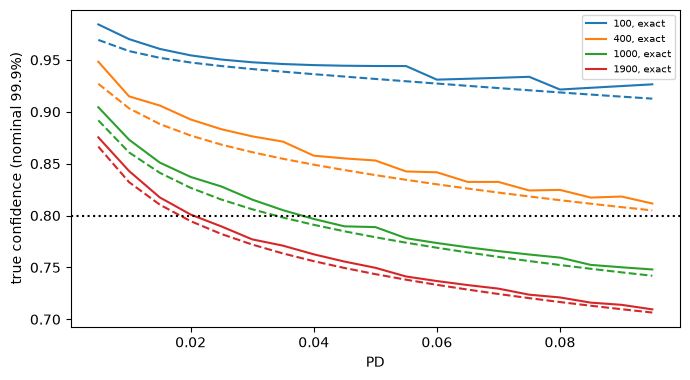

In [6]:
# True confidence of a 99.9% binomial test under Basel correlation, exact and by approximation
from riskvalidation.harness.exact import wp14_true_confidence
from riskvalidation.regulatory.irb import correlation

pds = np.array(out["exact_curves"][0]["x"])
fig, ax = plt.subplots(figsize=(7, 3.9))
for index, n in enumerate((100, 400, 1000, 1900)):
    rhos = [correlation("corporate", p) for p in pds]
    tails = [rejection_probability("pd.binomial", n, p, 0.001, rho_true=r)["probability"] for p, r in zip(pds, rhos)]
    exact_y = [1 - t for t in tails]
    approx_y = [wp14_true_confidence(p, n, r, 0.999) for p, r in zip(pds, rhos)]
    ax.plot(pds, exact_y, color=f"C{index}", label=f"{n}, exact")
    ax.plot(pds, approx_y, color=f"C{index}", linestyle="--")
    print(f"n = {n:4d} | true confidence, exact: from {max(exact_y):.3f} to {min(exact_y):.3f}")
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("PD")
ax.set_ylabel("true confidence (nominal 99.9%)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

The dashed approximation follows the exact curve closely for the larger pools, and both fall as the pool grows: for 100 obligors the true confidence stays between 0.984 and 0.921, for 400 between 0.948 and 0.812, for 1,000 between 0.904 and 0.748 and for 1,900 between 0.875 and 0.710. The dotted line marks 80%: for a pool of 1,000 or more, a test sold as 99.9% confident has a true confidence that falls below 0.8 for part of the PD range, a true size above 20%. Larger pools make the problem worse, not better.

### Step 5: one scenario of the paper, rerun with a new seed

The paper ran the normal and traffic-lights tests over five years of 1,000 obligors with 25,000 runs per scenario. Scenario DC_LC of its Table 5 has a factor correlation of 0.2 across years, an asset correlation of 5% each year and a PD of 3%. The next cell builds it with `DefaultCounts.over_years`, runs both tests with 25,000 repetitions and a seed the paper never saw, and sets each type I error against the published one with `agrees_with_published`.

DC_LC, normal    0.05 | published 0.070 | new run 0.0704 | z +0.16 | True
DC_LC, normal    0.01 | published 0.026 | new run 0.0265 | z +0.36 | True
DC_LC, traffic   0.05 | published 0.113 | new run 0.1161 | z +1.08 | True
DC_LC, traffic   0.01 | published 0.024 | new run 0.0235 | z -0.35 | True


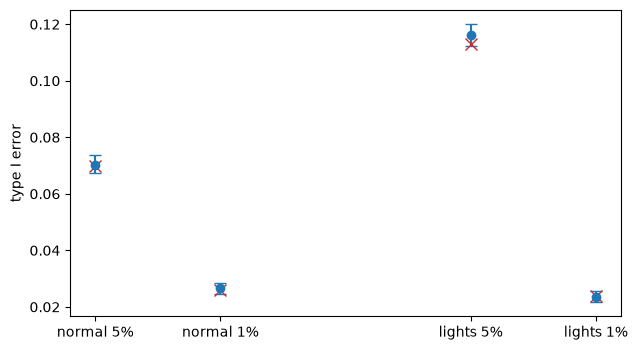

In [7]:
# Rerun scenario DC_LC of WP14 Table 5 with a new seed against the published errors
from riskvalidation.harness.rates import agrees_with_published

scenario = DefaultCounts.over_years([1000] * 5, [0.03] * 5, rho=0.05, theta=0.2)
published = {(c["row"], c["column"]): c["published"] for c in golden["cells"] if c["table"] == "Table 7"}
fig, ax = plt.subplots(figsize=(6.5, 3.6))
cases = (("pd.normal_multiperiod", {}, "DC_LC, normal"), ("pd.traffic_lights", {"ties": "upper"}, "DC_LC, traffic"))
for position, (test, kw, name) in enumerate(cases):
    run = simulate(test, scenario, n_rep=25000, seed=2026, feed=feed_series(), test_kwargs=kw)
    for shift, (rule, level) in enumerate((("p<0.05", "0.05"), ("p<0.01", "0.01"))):
        measured, pub = run.rates[rule], published[(name, level)]
        ok, z = agrees_with_published(measured, pub, golden["runs_published"])
        low, high = measured.interval
        print(f"{name:16s} {level} | published {pub:.3f} | new run {measured.rate:.4f} | z {z:+.2f} | {ok}")
        x = position * 3 + shift
        errors = [[measured.rate - low], [high - measured.rate]]
        ax.errorbar(x, measured.rate, yerr=errors, fmt="o", capsize=4, color="tab:blue")
        ax.plot(x, pub, "x", color="tab:red", markersize=9)
ax.set_xticks([0, 1, 3, 4])
ax.set_xticklabels(["normal 5%", "normal 1%", "lights 5%", "lights 1%"])
ax.set_ylabel("type I error")
fig.tight_layout()
plt.show()

All four type I errors agree with the paper: the normal test gives 0.0704 at 5% against the published 0.070 and 0.0265 at 1% against 0.026, and the traffic lights give 0.1161 against 0.113 and 0.0235 against 0.024, with standardised differences between -0.35 and 1.08. This is an independent rerun, with the engine and a new seed, and it lands within Monte Carlo error of numbers printed in 2005. The traffic-lights size of 0.1161 is also the clearest single illustration of the paper's thesis: with correlated years, a 5% test rejects a right model one time in nine.

### Step 6: Tables 7 and 8, cell by cell

The paper printed the type I error (Table 7) and the type II error (Table 8) of the two time-series tests at six levels in many scenarios. The file keeps the 144 published cells with the rate the engine measured. The next cell computes the standardised difference of every cell with `agrees_with_published` and prints how many agree, the mean and largest difference, and any cell that does not, then draws the histogram of the differences with the 3.29 limit.

cells: 144 | mean z: -0.112
largest absolute z: 5.81
cells that agree: 143 | that disagree: 1
('Table 8', 'DV_LV, traffic', '0.001', 0.955, 0.9436)


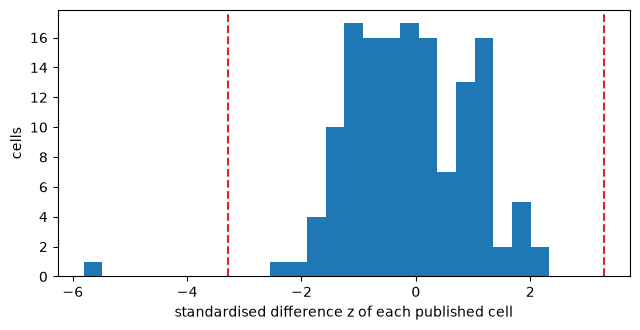

In [8]:
# Standardised difference of every published cell of WP14 Tables 7 and 8
from riskvalidation.harness.rates import Rate

n_runs = golden["runs"]
zs, misses = [], []
for cell in golden["cells"]:
    measured = Rate(round(cell["measured"] * n_runs), n_runs)
    ok, z = agrees_with_published(measured, cell["published"], golden["runs_published"])
    zs.append(z)
    if not ok:
        misses.append((cell["table"], cell["row"], cell["column"], cell["published"], round(cell["measured"], 4)))
print("cells:", len(zs), "| mean z:", round(float(np.mean(zs)), 3))
print("largest absolute z:", round(float(np.max(np.abs(zs))), 2))
print("cells that agree:", len(zs) - len(misses), "| that disagree:", len(misses))
for miss in misses:
    print(miss)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(zs, bins=25, color="tab:blue")
ax.axvline(-3.29, color="tab:red", linestyle="--")
ax.axvline(3.29, color="tab:red", linestyle="--")
ax.set_xlabel("standardised difference z of each published cell")
ax.set_ylabel("cells")
fig.tight_layout()
plt.show()

The differences centre on zero, with a mean of -0.112, so the engine sits slightly below the paper on average, and 143 of the 144 cells agree. The exception is Table 8, scenario DV_LV, traffic lights, at level 0.001: the paper prints 0.955 and the engine measures 0.9436, a standardised difference of 5.81 in absolute value. It is the only disagreement among 144 cells, so the neighbouring levels of that row agree, and the printed cell looks like a slip of the paper rather than a flaw of the engine. A reproduction should state its exception, not hide it.

## Results

**Answer:** An asset correlation of 5%, a default correlation of only 0.410%, multiplies the variance of the default count of 1,000 obligors by 5.10 and lifts the exact size of the binomial test at 5% from 0.0479 to 0.1775; at 10% the size is 0.1969. The tests with no closed form suffer as well: Hosmer-Lemeshow reaches 0.868 and the chi-square over grades 0.871 at an asset correlation of 20%. The engine reproduces the working paper: the rerun of scenario DC_LC agrees within Monte Carlo error (0.0704 against 0.070 for the normal test at 5%), and 143 of the 144 published cells agree.

- **The exact size settles the count tests.** The corrected test sits at 0.0146 at an asset correlation of 5%, under its level, and at 0.0711 at 20%, over it, because it assumes 12%.
- **The time-series tests err in both directions.** The normal test falls to 0.039 at 20% while the traffic lights reach 0.1161 in the scenario of the paper.
- **A large pool does not help.** For 1,900 obligors the true confidence of a 99.9% test falls as low as 0.710.
- **The one disagreement is explained.** Table 8, DV_LV, traffic lights, level 0.001 shows 5.81 standardised units, and as the only one of 144 it points to the print.

The power under clustering, where the paper concludes that no really powerful test exists, is taken up in the state-of-the-art notebook of the topic.

## Summary

- A small asset correlation is a small default correlation and a large variance of the default count: a factor of 5.10 at 5% for 1,000 obligors.
- The binomial and Jeffreys tests, which assume independence, have an exact size of 0.1775 to 0.1969 at a nominal 5% once the asset correlation is 5% or more.
- The Vasicek correction is right only when its assumed correlation is the true one.
- The tests for grades and obligors over-reject under clustering; the time-series tests can under-reject or over-reject depending on the scenario.
- The engine reruns the working paper: a scenario with a new seed agrees, and 143 of 144 published cells agree, with the exception explained.

**What to try next.** Rerun step 5 with the independent-years scenarios of Table 5 and compare the sizes with the clustered ones, then read notebook 05.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial test and its true size under correlation (appendix, Figure 9), the simulation study of the normal and traffic-lights tests (pages 61 to 67, Tables 5 to 8). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.